# CSE412 Big Data Project: Hospital Readmission Risk Prediction & Healthcare Analytics
**Course:** CSE412 — Big Data & Large-Scale Computing  
**Architecture:** Raw CSV → HDFS → Apache Pig ETL → Cleaned HDFS → Apache Hive Warehouse & Analytics → Prepared Export → Apache Spark MLlib (Classification)  
**Dataset:** UCI Diabetes 130-US Hospitals (1999–2008) — Optimized 10,000-Row Stratified Sample for Local Environment Execution  


## 0. Project Configuration and Environment Diagnostics
This cell defines all paths, Big Data service connection URIs, and resource settings.
The pipeline is designed to execute on WSL Ubuntu using genuine local Hadoop/Pig/Hive/Spark services.

In [1]:
import os
import sys
import shutil
import subprocess
import urllib.request
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np

# Set Environment Variables for Big Data Tools
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'
os.environ['HADOOP_HOME'] = '/home/manic/hadoop'
os.environ['HADOOP_CONF_DIR'] = '/home/manic/hadoop/etc/hadoop'
os.environ['PIG_HOME'] = '/home/manic/pig/pig-0.17.0'
os.environ['PIG_CLASSPATH'] = '/home/manic/hadoop/etc/hadoop'
os.environ['HIVE_HOME'] = '/home/manic/hive'
os.environ['SPARK_HOME'] = '/home/manic/spark'
os.environ['HADOOP_OPTS'] = '-Dorg.jline.terminal.dumb=true'
os.environ['HADOOP_CLIENT_OPTS'] = '-Dorg.jline.terminal.dumb=true'
os.environ['TERM'] = 'dumb'
os.environ['PATH'] = f"{os.environ['HADOOP_HOME']}/bin:{os.environ['PIG_HOME']}/bin:{os.environ['HIVE_HOME']}/bin:{os.environ['SPARK_HOME']}/bin:{os.environ['PATH']}"
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

# Directory Layout
PROJECT_DIR = Path('/home/manic/project')
DATA_DIR = PROJECT_DIR / 'data'
RAW_DIR = DATA_DIR / 'raw'
SCRIPTS_DIR = PROJECT_DIR / 'scripts'
RESULTS_DIR = PROJECT_DIR / 'results'
LOGS_DIR = PROJECT_DIR / 'logs'

for p in [DATA_DIR, RAW_DIR, SCRIPTS_DIR, RESULTS_DIR, LOGS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Service Endpoints
HDFS_URI = 'hdfs://localhost:9000'
HDFS_ROOT = '/cse412_hospital_readmission'
HDFS_RAW = f"{HDFS_ROOT}/raw/diabetes_sample.csv"
HDFS_PIG_OUT = f"{HDFS_ROOT}/pig/cleaned"
HDFS_HIVE_MODEL_DIR = f"{HDFS_ROOT}/hive/model_input"

HIVE_JDBC_URL = 'jdbc:hive2://localhost:10000'
HIVE_USER = 'manic'
HIVE_DB = 'cse412_readmission'
SPARK_MASTER = 'local[2]'

SAMPLE_CSV_PATH = DATA_DIR / 'diabetes_sample.csv'
RAW_CSV_PATH = RAW_DIR / 'diabetic_data.csv'

print('=== Project Environment Initialized ===')
print('Project Dir   :', PROJECT_DIR)
print('HDFS Raw Path :', HDFS_RAW)
print('Pig Output    :', HDFS_PIG_OUT)
print('Hive Model Dir:', HDFS_HIVE_MODEL_DIR)
print('Hive JDBC URL :', HIVE_JDBC_URL)


=== Project Environment Initialized ===
Project Dir   : /home/manic/project
HDFS Raw Path : /cse412_hospital_readmission/raw/diabetes_sample.csv
Pig Output    : /cse412_hospital_readmission/pig/cleaned
Hive Model Dir: /cse412_hospital_readmission/hive/model_input
Hive JDBC URL : jdbc:hive2://localhost:10000


In [2]:
def run_cmd(args, check=True, tail=10000, input_data=None):
    """Helper function to execute system commands cleanly with diagnostic output."""
    cmd_str = ' '.join(map(str, args)) if isinstance(args, list) else str(args)
    print(f"$ {cmd_str[:120]} ...")
    shell = isinstance(args, str)
    env = os.environ.copy()
    env['TERM'] = 'dumb'
    proc = subprocess.run(
        args, env=env, shell=shell, input=input_data,
        stdin=subprocess.DEVNULL if input_data is None else None,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
    )
    out = proc.stdout or ''
    if tail and len(out) > tail:
        print(out[-tail:])
    else:
        print(out)
    if check and proc.returncode != 0:
        raise RuntimeError(f"Command failed (code {proc.returncode}): {cmd_str[:120]}")
    return proc

# Verify CLI tool availability
for tool in ['hdfs', 'pig', 'beeline', 'spark-submit']:
    path = shutil.which(tool)
    print(f"  {tool:12} -> {path or 'NOT FOUND'}")


  hdfs         -> /home/manic/hadoop/bin/hdfs
  pig          -> /home/manic/pig/pig-0.17.0/bin/pig
  beeline      -> /home/manic/hive/bin/beeline
  spark-submit -> /home/manic/spark/bin/spark-submit


## 1. Stage 1 — Dataset Ingestion and 3-Way Equal Class Sampling
We use the official UCI Diabetes 130-US Hospitals dataset (101,766 encounters across 130 hospitals from 1999–2008).
To balance class representation across the dataset and eliminate severe majority-class bias during model training, we take an **equal quantity of data for all classes** from the dataset:
- **`NO`**: 3,333 encounters (33.33%)
- **`>30`**: 3,333 encounters (33.33%)
- **`<30`**: 3,334 encounters (33.34%)
**Total: 10,000 encounters** with 8,991 unique patients.

The downstream binary classification target is defined as:
- **`label = 1`**: Readmitted within 30 days (`<30`) — clinical intervention group (33.34%).
- **`label = 0`**: Other outcomes (`>30` or `NO`) (66.66%).


In [3]:
sample_df = pd.read_csv(SAMPLE_CSV_PATH)
print(f"Sample Dataset Loaded: {len(sample_df):,} rows, {len(sample_df.columns)} columns")
print("\n--- Target Distribution (Equal 3-Way Sampling) ---")
print(sample_df['readmitted'].value_counts())
print("\n--- Target Percentages ---")
print((sample_df['readmitted'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

print(f"\nUnique Patients in Sample: {sample_df['patient_nbr'].nunique():,}")

# Binary target representation
sample_df['target_label'] = (sample_df['readmitted'] == '<30').astype(int)
print("\n--- Binary Classification Target ---")
print(sample_df['target_label'].value_counts().rename({0: 'Other / No Readmit (0)', 1: 'Readmit <30 Days (1)'}))

sample_df[['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'time_in_hospital', 'num_medications', 'readmitted', 'target_label']].head(6)


Sample Dataset Loaded: 10,000 rows, 50 columns

--- Target Distribution (Equal 3-Way Sampling) ---
readmitted
<30    3334
>30    3333
NO     3333
Name: count, dtype: int64

--- Target Percentages ---
readmitted
<30    33.34%
>30    33.33%
NO     33.33%
Name: proportion, dtype: str

Unique Patients in Sample: 8,991

--- Binary Classification Target ---
target_label
Other / No Readmit (0)    6666
Readmit <30 Days (1)      3334
Name: count, dtype: int64


,encounter_id,patient_nbr,race,gender,age,time_in_hospital,num_medications,readmitted,target_label
0,80874054,23532534,Caucasian,Female,[70-80),4,17,>30,0
1,3077586,430092,Caucasian,Male,[60-70),2,15,>30,0
2,70128306,975213,Caucasian,Female,[80-90),13,15,NO,0
3,169899780,91160280,AfricanAmerican,Female,[50-60),5,18,>30,0
4,217674348,112735458,Caucasian,Male,[80-90),4,26,>30,0
5,78067728,26139852,Caucasian,Female,[40-50),6,12,>30,0


## 2. Stage 2 — HDFS Storage Ingestion
We create dedicated HDFS project directories and upload `diabetes_sample.csv` to distributed storage.
All subsequent processing in Pig and Hive reads directly from HDFS.


In [4]:
run_cmd(["hdfs", "dfs", "-mkdir", "-p", f"{HDFS_ROOT}/raw"])
run_cmd(["hdfs", "dfs", "-put", "-f", str(SAMPLE_CSV_PATH), HDFS_RAW])
run_cmd(["hdfs", "dfs", "-ls", "-h", f"{HDFS_ROOT}/raw"])
print("\n[CHECKPOINT PASSED] Raw dataset verified in HDFS distributed storage.")


$ hdfs dfs -mkdir -p /cse412_hospital_readmission/raw ...


2026-10-16 09:53:57,517 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable

$ hdfs dfs -put -f /home/manic/project/data/diabetes_sample.csv /cse412_hospital_readmission/raw/diabetes_sample.csv ...


2026-10-16 09:53:58,868 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable

$ hdfs dfs -ls -h /cse412_hospital_readmission/raw ...


2026-10-16 09:54:00,371 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Found 1 items
-rw-r--r--   1 manic supergroup      1.7 M 2026-10-16 09:53 /cse412_hospital_readmission/raw/diabetes_sample.csv


[CHECKPOINT PASSED] Raw dataset verified in HDFS distributed storage.


## 3. Stage 3 — Apache Pig ETL & Transformation
We execute a genuine **Pig Latin** script using Apache Pig 0.17.0.
The script:
1. Loads raw comma-separated values from HDFS.
2. Filters out the CSV header row.
3. Filters for valid readmission outcomes (`<30`, `>30`, `NO`).
4. Projects analytical features, converts numeric fields to `int`, maps missing race values (`?` → `Unknown`), and computes binary label (`<30` → 1, else 0).
5. Drops null records and writes tab-separated records back to HDFS at `/cse412_hospital_readmission/pig/cleaned`.


In [5]:
pig_script = f"""
raw = LOAD '$INPUT' USING PigStorage(',') AS (
    f0:chararray, f1:chararray, f2:chararray, f3:chararray, f4:chararray,
    f5:chararray, f6:chararray, f7:chararray, f8:chararray, f9:chararray,
    f10:chararray, f11:chararray, f12:chararray, f13:chararray, f14:chararray,
    f15:chararray, f16:chararray, f17:chararray, f18:chararray, f19:chararray,
    f20:chararray, f21:chararray, f22:chararray, f23:chararray, f24:chararray,
    f25:chararray, f26:chararray, f27:chararray, f28:chararray, f29:chararray,
    f30:chararray, f31:chararray, f32:chararray, f33:chararray, f34:chararray,
    f35:chararray, f36:chararray, f37:chararray, f38:chararray, f39:chararray,
    f40:chararray, f41:chararray, f42:chararray, f43:chararray, f44:chararray,
    f45:chararray, f46:chararray, f47:chararray, f48:chararray, f49:chararray
);

-- Remove CSV header
without_header = FILTER raw BY f0 != 'encounter_id';

-- Filter for known target readmission values
known_target = FILTER without_header BY (f49 == '<30' OR f49 == '>30' OR f49 == 'NO');

-- Project ALL columns from dataset (50 attributes)
projected = FOREACH known_target GENERATE
    f1 AS patient_nbr,
    (f2 == '?' ? 'Unknown' : f2) AS race,
    f3 AS gender,
    f4 AS age,
    (f5 == '?' ? 'Unknown' : f5) AS weight,
    f6 AS admission_type_id,
    f7 AS discharge_disposition_id,
    f8 AS admission_source_id,
    (int)f9 AS time_in_hospital,
    (f10 == '?' ? 'Unknown' : f10) AS payer_code,
    (f11 == '?' ? 'Unknown' : f11) AS medical_specialty,
    (int)f12 AS num_lab_procedures,
    (int)f13 AS num_procedures,
    (int)f14 AS num_medications,
    (int)f15 AS number_outpatient,
    (int)f16 AS number_emergency,
    (int)f17 AS number_inpatient,
    (f18 == '?' ? 'Unknown' : f18) AS diag_1,
    (f19 == '?' ? 'Unknown' : f19) AS diag_2,
    (f20 == '?' ? 'Unknown' : f20) AS diag_3,
    (int)f21 AS number_diagnoses,
    (f22 == '?' ? 'None' : f22) AS max_glu_serum,
    (f23 == '?' ? 'None' : f23) AS A1Cresult,
    f24 AS metformin,
    f25 AS repaglinide,
    f26 AS nateglinide,
    f27 AS chlorpropamide,
    f28 AS glimepiride,
    f29 AS acetohexamide,
    f30 AS glipizide,
    f31 AS glyburide,
    f32 AS tolbutamide,
    f33 AS pioglitazone,
    f34 AS rosiglitazone,
    f35 AS acarbose,
    f36 AS miglitol,
    f37 AS troglitazone,
    f38 AS tolazamide,
    f39 AS examide,
    f40 AS citoglipton,
    f41 AS insulin,
    f42 AS glyburide_metformin,
    f43 AS glipizide_metformin,
    f44 AS glimepiride_pioglitazone,
    f45 AS metformin_rosiglitazone,
    f46 AS metformin_pioglitazone,
    f47 AS change,
    f48 AS diabetesMed,
    (f49 == '<30' ? 1 : 0) AS label;

-- Filter corrupted records
cleaned = FILTER projected BY
    patient_nbr IS NOT NULL AND patient_nbr != '' AND
    time_in_hospital IS NOT NULL AND
    num_lab_procedures IS NOT NULL AND
    num_procedures IS NOT NULL AND
    num_medications IS NOT NULL AND
    number_outpatient IS NOT NULL AND
    number_emergency IS NOT NULL AND
    number_inpatient IS NOT NULL AND
    number_diagnoses IS NOT NULL;

STORE cleaned INTO '$OUTPUT' USING PigStorage('\\t');
"""

PIG_SCRIPT_FILE = SCRIPTS_DIR / 'clean_hospital_data.pig'
PIG_SCRIPT_FILE.write_text(pig_script, encoding='utf-8')
print(f"Saved Pig Latin script: {PIG_SCRIPT_FILE}")

# Clean previous Pig output directory in HDFS
run_cmd(["hdfs", "dfs", "-rm", "-r", "-f", HDFS_PIG_OUT], check=False)

# Execute Pig script using LocalJobRunner for single-node efficiency
run_cmd([
    "pig", "-Dmapreduce.framework.name=local",
    "-param", f"INPUT={HDFS_RAW}",
    "-param", f"OUTPUT={HDFS_PIG_OUT}",
    str(PIG_SCRIPT_FILE)
], tail=4000)

run_cmd(["hdfs", "dfs", "-ls", HDFS_PIG_OUT])
print("\n[CHECKPOINT PASSED] Apache Pig ETL completed. Cleaned dataset saved to HDFS.")


Saved Pig Latin script: /home/manic/project/scripts/clean_hospital_data.pig
$ hdfs dfs -rm -r -f /cse412_hospital_readmission/pig/cleaned ...


2026-10-16 09:54:01,568 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Deleted /cse412_hospital_readmission/pig/cleaned

$ pig -Dmapreduce.framework.name=local -param INPUT=/cse412_hospital_readmission/raw/diabetes_sample.csv -param OUTPUT=/cs ...


nner Map Task Executor #0] INFO  org.apache.hadoop.mapred.Task - Final Counters for attempt_local726068836_0001_m_000000_0: Counters: 21
	File System Counters
		FILE: Number of bytes read=471
		FILE: Number of bytes written=6684339
		FILE: Number of read operations=0
		FILE: Number of large read operations=0
		FILE: Number of write operations=0
		HDFS: Number of bytes read=7560346
		HDFS: Number of bytes written=7559626
		HDFS: Number of read operations=46
		HDFS: Number of large read operations=0
		HDFS: Number of write operations=13
		HDFS: Number of bytes read erasure-coded=0
	Map-Reduce Framework
		Map input records=10001
		Map output records=10000
		Input split bytes=400
		Spilled Records=0
		Failed Shuffles=0
		Merged Map outputs=0
		GC time elapsed (ms)=16
		Total committed heap usage (bytes)=94371840
	File Input Format Counters 
		Bytes Read=0
	File Output Format Counters 
		Bytes Written=0
2026-10-16 09:54:07,367 [LocalJobRunner Map Task Executor #0] INFO  org.apache.hadoop.ma

2026-10-16 09:54:11,880 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Found 2 items
-rw-r--r--   1 manic supergroup          0 2026-10-16 09:54 /cse412_hospital_readmission/pig/cleaned/_SUCCESS
-rw-r--r--   1 manic supergroup    1803844 2026-10-16 09:54 /cse412_hospital_readmission/pig/cleaned/part-m-00000


[CHECKPOINT PASSED] Apache Pig ETL completed. Cleaned dataset saved to HDFS.


## 4. Stage 4 — Apache Hive Warehousing, Analytics & Export
In this stage, we use **Apache Hive 4.2.0** connected via HiveServer2 and Beeline:
1. Create a dedicated database: `cse412_readmission`.
2. Define an external table `cleaned_encounters` over the Pig-cleaned HDFS files.
3. Execute analytical queries to investigate readmission patterns across patient age groups and gender.
4. Export the finalized feature table to `hdfs://localhost:9000/cse412_hospital_readmission/hive/model_input` for Spark MLlib.


In [6]:
hive_setup_sql = f"""
SET mapreduce.framework.name=local;
SET hive.exec.mode.local.auto=true;

CREATE DATABASE IF NOT EXISTS {HIVE_DB};

DROP TABLE IF EXISTS {HIVE_DB}.cleaned_encounters;

CREATE EXTERNAL TABLE {HIVE_DB}.cleaned_encounters (
    patient_nbr STRING,
    race STRING,
    gender STRING,
    age STRING,
    weight STRING,
    admission_type_id STRING,
    discharge_disposition_id STRING,
    admission_source_id STRING,
    time_in_hospital INT,
    payer_code STRING,
    medical_specialty STRING,
    num_lab_procedures INT,
    num_procedures INT,
    num_medications INT,
    number_outpatient INT,
    number_emergency INT,
    number_inpatient INT,
    diag_1 STRING,
    diag_2 STRING,
    diag_3 STRING,
    number_diagnoses INT,
    max_glu_serum STRING,
    A1Cresult STRING,
    metformin STRING,
    repaglinide STRING,
    nateglinide STRING,
    chlorpropamide STRING,
    glimepiride STRING,
    acetohexamide STRING,
    glipizide STRING,
    glyburide STRING,
    tolbutamide STRING,
    pioglitazone STRING,
    rosiglitazone STRING,
    acarbose STRING,
    miglitol STRING,
    troglitazone STRING,
    tolazamide STRING,
    examide STRING,
    citoglipton STRING,
    insulin STRING,
    glyburide_metformin STRING,
    glipizide_metformin STRING,
    glimepiride_pioglitazone STRING,
    metformin_rosiglitazone STRING,
    metformin_pioglitazone STRING,
    change STRING,
    diabetesMed STRING,
    label INT
)
ROW FORMAT DELIMITED
FIELDS TERMINATED BY '\\t'
STORED AS TEXTFILE
LOCATION '{HDFS_PIG_OUT}';

-- Verify table record count
SELECT COUNT(*) AS total_cleaned_records FROM {HIVE_DB}.cleaned_encounters;

-- Export prepared features to HDFS for Spark MLlib
INSERT OVERWRITE DIRECTORY '{HDFS_HIVE_MODEL_DIR}'
ROW FORMAT DELIMITED
FIELDS TERMINATED BY '\\t'
SELECT * FROM {HIVE_DB}.cleaned_encounters;
"""

HIVE_SETUP_FILE = SCRIPTS_DIR / 'create_hive_table_and_export.sql'
HIVE_SETUP_FILE.write_text(hive_setup_sql, encoding='utf-8')
print(f"Saved HiveQL setup script: {HIVE_SETUP_FILE}")

# Execute Hive setup and materialization via Beeline using -e
run_cmd([
    "beeline", "-u", HIVE_JDBC_URL, "-n", HIVE_USER,
    "-e", hive_setup_sql
], tail=4000)

run_cmd(["hdfs", "dfs", "-ls", HDFS_HIVE_MODEL_DIR])
print("\n[CHECKPOINT PASSED] Apache Hive external table created and feature dataset exported in HDFS.")


Saved HiveQL setup script: /home/manic/project/scripts/create_hive_table_and_export.sql
$ beeline -u jdbc:hive2://localhost:10000 -n manic -e 
SET mapreduce.framework.name=local;
SET hive.exec.mode.local.auto=t ...


eldSchema(name:cleaned_encounters.pioglitazone, type:string, comment:null), FieldSchema(name:cleaned_encounters.rosiglitazone, type:string, comment:null), FieldSchema(name:cleaned_encounters.acarbose, type:string, comment:null), FieldSchema(name:cleaned_encounters.miglitol, type:string, comment:null), FieldSchema(name:cleaned_encounters.troglitazone, type:string, comment:null), FieldSchema(name:cleaned_encounters.tolazamide, type:string, comment:null), FieldSchema(name:cleaned_encounters.examide, type:string, comment:null), FieldSchema(name:cleaned_encounters.citoglipton, type:string, comment:null), FieldSchema(name:cleaned_encounters.insulin, type:string, comment:null), FieldSchema(name:cleaned_encounters.glyburide_metformin, type:string, comment:null), FieldSchema(name:cleaned_encounters.glipizide_metformin, type:string, comment:null), FieldSchema(name:cleaned_encounters.glimepiride_pioglitazone, type:string, comment:null), FieldSchema(name:cleaned_encounters.metformin_rosiglitazone,

2026-10-16 09:54:22,902 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Found 1 items
-rw-r--r--   1 manic supergroup    1803844 2026-10-16 09:54 /cse412_hospital_readmission/hive/model_input/000000_0


[CHECKPOINT PASSED] Apache Hive external table created and feature dataset exported in HDFS.


In [7]:
def run_hive_query(query_sql, description):
    """Execute analytical SQL queries in Hive and print results."""
    print(f"\n=== {description} ===")
    full_sql = f"SET mapreduce.framework.name=local;\nSET hive.exec.mode.local.auto=true;\n{query_sql.strip()}"
    run_cmd([
        "beeline", "-u", HIVE_JDBC_URL, "-n", HIVE_USER,
        "-e", full_sql
    ], tail=3000)

run_hive_query(f"""
SELECT age, COUNT(*) AS encounter_count,
       ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM {HIVE_DB}.cleaned_encounters
GROUP BY age
ORDER BY age;
""", "Readmission Rate Across Age Groups")

run_hive_query(f"""
SELECT gender, COUNT(*) AS encounter_count,
       ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM {HIVE_DB}.cleaned_encounters
GROUP BY gender
ORDER BY encounter_count DESC;
""", "Readmission Rate Across Genders")

run_hive_query(f"""
SELECT CASE WHEN number_inpatient = 0 THEN '0 Prior Inpatient'
            WHEN number_inpatient = 1 THEN '1 Prior Inpatient'
            ELSE '2+ Prior Inpatient' END AS inpatient_history,
       COUNT(*) AS encounter_count,
       ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM {HIVE_DB}.cleaned_encounters
GROUP BY CASE WHEN number_inpatient = 0 THEN '0 Prior Inpatient'
              WHEN number_inpatient = 1 THEN '1 Prior Inpatient'
              ELSE '2+ Prior Inpatient' END
ORDER BY encounter_count DESC;
""", "Readmission Rate by Prior Inpatient Admissions")



=== Readmission Rate Across Age Groups ===
$ beeline -u jdbc:hive2://localhost:10000 -n manic -e SET mapreduce.framework.name=local;
SET hive.exec.mode.local.auto=tr ...


ge the average load for a reducer (in bytes):
INFO  :   set hive.exec.reducers.bytes.per.reducer=<number>
INFO  : In order to limit the maximum number of reducers:
INFO  :   set hive.exec.reducers.max=<number>
INFO  : In order to set a constant number of reducers:
INFO  :   set mapreduce.job.reduces=<number>
INFO  : number of splits:1
INFO  : Submitting tokens for job: job_local1109758594_0033
INFO  : Executing with tokens: []
INFO  : The url to track the job: http://localhost:8080/
INFO  : Job running in-process (local Hadoop)
INFO  : 2026-10-16 09:54:31,628 Stage-1 map = 0%,  reduce = 0%
INFO  : 2026-10-16 09:54:32,630 Stage-1 map = 100%,  reduce = 100%, Cumulative CPU 3.75 sec
INFO  : MapReduce Total cumulative CPU time: 3 seconds 750 msec
INFO  : Ended Job = job_local1109758594_0033
INFO  : Launching Job 2 out of 2
INFO  : Starting task [Stage-2:MAPRED] in serial mode
INFO  : Number of reduce tasks determined at compile time: 1
INFO  : In order to change the average load for a redu

unters
GROUP BY gender
ORDER BY encounter_count DESC
WARN  : Hive-on-MR is deprecated in Hive 2 and may not be available in the future versions. Consider using a different execution engine (i.e. tez) or using Hive 1.X releases.
INFO  : Query ID = manic_20261016095437_08530e72-dac3-414f-ab8f-eff422ec1a47
INFO  : Total jobs = 2
INFO  : Launching Job 1 out of 2
INFO  : Starting task [Stage-1:MAPRED] in serial mode
INFO  : Number of reduce tasks not specified. Estimated from input data size: 1
INFO  : In order to change the average load for a reducer (in bytes):
INFO  :   set hive.exec.reducers.bytes.per.reducer=<number>
INFO  : In order to limit the maximum number of reducers:
INFO  :   set hive.exec.reducers.max=<number>
INFO  : In order to set a constant number of reducers:
INFO  :   set mapreduce.job.reduces=<number>
INFO  : number of splits:1
INFO  : Submitting tokens for job: job_local106091126_0035
INFO  : Executing with tokens: []
INFO  : The url to track the job: http://localhost:

ersions. Consider using a different execution engine (i.e. tez) or using Hive 1.X releases.
INFO  : Query ID = manic_20261016095444_3b91d2eb-9e86-4f6d-9466-1313104673f3
INFO  : Total jobs = 2
INFO  : Launching Job 1 out of 2
INFO  : Starting task [Stage-1:MAPRED] in serial mode
INFO  : Number of reduce tasks not specified. Estimated from input data size: 1
INFO  : In order to change the average load for a reducer (in bytes):
INFO  :   set hive.exec.reducers.bytes.per.reducer=<number>
INFO  : In order to limit the maximum number of reducers:
INFO  :   set hive.exec.reducers.max=<number>
INFO  : In order to set a constant number of reducers:
INFO  :   set mapreduce.job.reduces=<number>
INFO  : number of splits:1
INFO  : Submitting tokens for job: job_local1424097761_0037
INFO  : Executing with tokens: []
INFO  : The url to track the job: http://localhost:8080/
INFO  : Job running in-process (local Hadoop)
INFO  : 2026-10-16 09:54:46,140 Stage-1 map = 100%,  reduce = 100%, Cumulative CPU 

## 5. Stage 5 — Apache Spark MLlib Classification Pipeline (All Dataset Columns)
We now initialize **Apache Spark 3.5.9** and load all columns from HDFS.
Key considerations:
1. **Patient-level Split:** Partitioning on `patient_nbr` ensures multiple encounters for the same patient never cross folds.
2. **Clinical Disease Categorization (ICD-9):** Rather than treating 450+ raw ICD-9 diagnosis codes as noisy high-cardinality levels, we map primary, secondary, and tertiary diagnoses (`diag_1`, `diag_2`, `diag_3`) into the 9 standard clinical disease categories (Circulatory, Diabetes, Respiratory, Digestive, Injury, Musculoskeletal, Genitourinary, Neoplasms, Other) as established in published medical informatics research (Strack et al., 2014).
3. **Comprehensive Feature Vector:** Assembles 32 categorical clinical attributes (including 17 active diabetes medications, admission/discharge contexts, glycemic indicators) and 8 numeric hospital metrics into a rich feature vector.
4. **Model Training & Evaluation:** Trains Logistic Regression and Random Forest using accuracy, precision, recall, F1, and ROC-AUC.


In [8]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Initialize SparkSession configured for local cluster execution
spark = (SparkSession.builder
         .appName("CSE412-Hospital-Readmission-Small")
         .master(SPARK_MASTER)
         .config("spark.hadoop.fs.defaultFS", HDFS_URI)
         .config("spark.sql.shuffle.partitions", "4")
         .config("spark.driver.memory", "1g")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print(f"Spark Session Active — Version: {spark.version}")

# Define schema matching Hive exported features (all columns)
schema = StructType([
    StructField("patient_nbr", StringType(), True),
    StructField("race", StringType(), True),
    StructField("gender", StringType(), True),
    StructField("age", StringType(), True),
    StructField("weight", StringType(), True),
    StructField("admission_type_id", StringType(), True),
    StructField("discharge_disposition_id", StringType(), True),
    StructField("admission_source_id", StringType(), True),
    StructField("time_in_hospital", IntegerType(), True),
    StructField("payer_code", StringType(), True),
    StructField("medical_specialty", StringType(), True),
    StructField("num_lab_procedures", IntegerType(), True),
    StructField("num_procedures", IntegerType(), True),
    StructField("num_medications", IntegerType(), True),
    StructField("number_outpatient", IntegerType(), True),
    StructField("number_emergency", IntegerType(), True),
    StructField("number_inpatient", IntegerType(), True),
    StructField("diag_1", StringType(), True),
    StructField("diag_2", StringType(), True),
    StructField("diag_3", StringType(), True),
    StructField("number_diagnoses", IntegerType(), True),
    StructField("max_glu_serum", StringType(), True),
    StructField("A1Cresult", StringType(), True),
    StructField("metformin", StringType(), True),
    StructField("repaglinide", StringType(), True),
    StructField("nateglinide", StringType(), True),
    StructField("chlorpropamide", StringType(), True),
    StructField("glimepiride", StringType(), True),
    StructField("acetohexamide", StringType(), True),
    StructField("glipizide", StringType(), True),
    StructField("glyburide", StringType(), True),
    StructField("tolbutamide", StringType(), True),
    StructField("pioglitazone", StringType(), True),
    StructField("rosiglitazone", StringType(), True),
    StructField("acarbose", StringType(), True),
    StructField("miglitol", StringType(), True),
    StructField("troglitazone", StringType(), True),
    StructField("tolazamide", StringType(), True),
    StructField("examide", StringType(), True),
    StructField("citoglipton", StringType(), True),
    StructField("insulin", StringType(), True),
    StructField("glyburide_metformin", StringType(), True),
    StructField("glipizide_metformin", StringType(), True),
    StructField("glimepiride_pioglitazone", StringType(), True),
    StructField("metformin_rosiglitazone", StringType(), True),
    StructField("metformin_pioglitazone", StringType(), True),
    StructField("change", StringType(), True),
    StructField("diabetesMed", StringType(), True),
    StructField("label", IntegerType(), True),
])

# Read directly from HDFS directory produced by Hive
spark_df = (spark.read
            .option("sep", "\t")
            .schema(schema)
            .csv(f"{HDFS_URI}{HDFS_HIVE_MODEL_DIR}"))

total_records = spark_df.count()
print(f"Total records loaded into Spark: {total_records:,}")
spark_df.groupBy("label").count().show()


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/16 09:54:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark Session Active — Version: 3.5.9


Total records loaded into Spark: 10,000


+-----+-----+
|label|count|
+-----+-----+
|    0| 6666|
|    1| 3334|
+-----+-----+



In [9]:
# Clinical Disease Grouping UDF (ICD-9 mapping from Strack et al., 2014)
@F.udf(returnType=StringType())
def map_icd9(val):
    if not val or val == '?' or str(val).strip() == '':
        return 'Missing'
    val = str(val).strip()
    if val.startswith('250'):
        return 'Diabetes'
    try:
        code = float(val)
        if (390 <= code <= 459) or code == 785:
            return 'Circulatory'
        elif (460 <= code <= 519) or code == 786:
            return 'Respiratory'
        elif (520 <= code <= 579) or code == 787:
            return 'Digestive'
        elif (580 <= code <= 629) or code == 788:
            return 'Genitourinary'
        elif (140 <= code <= 239):
            return 'Neoplasms'
        elif (710 <= code <= 739):
            return 'Musculoskeletal'
        elif (800 <= code <= 999):
            return 'Injury'
        else:
            return 'Other'
    except:
        return 'Other'

# Add disease category columns
spark_df = (spark_df
            .withColumn("diag_1_group", map_icd9(F.col("diag_1")))
            .withColumn("diag_2_group", map_icd9(F.col("diag_2")))
            .withColumn("diag_3_group", map_icd9(F.col("diag_3"))))

# Deterministic patient-level train/test split (80% train, 20% test)
partition_key = F.pmod(F.xxhash64(F.col("patient_nbr")), F.lit(100))
train_raw = spark_df.filter(partition_key < 80).cache()
test_raw = spark_df.filter(partition_key >= 80).cache()

train_count, test_count = train_raw.count(), test_raw.count()
print(f"Patient-level split completed:")
print(f"  Training Encounters: {train_count:,} ({train_count/total_records:.1%})")
print(f"  Testing Encounters : {test_count:,} ({test_count/total_records:.1%})")

# Define 40 clinical feature columns across all dataset attributes
categorical_cols = [
    "race", "gender", "age", "weight", "admission_type_id",
    "discharge_disposition_id", "admission_source_id", "payer_code",
    "medical_specialty", "max_glu_serum", "A1Cresult",
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
    "tolazamide", "insulin", "glyburide_metformin", "glipizide_metformin",
    "change", "diabetesMed", "diag_1_group", "diag_2_group", "diag_3_group"
]
numeric_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

indexed_cols = [c + "_idx" for c in categorical_cols]
encoded_cols = [c + "_ohe" for c in categorical_cols]

# Build MLlib preprocessing pipeline
preprocessor = Pipeline(stages=[
    StringIndexer(inputCols=categorical_cols, outputCols=indexed_cols, handleInvalid="keep"),
    OneHotEncoder(inputCols=indexed_cols, outputCols=encoded_cols, handleInvalid="keep"),
    VectorAssembler(inputCols=numeric_cols + encoded_cols, outputCol="features", handleInvalid="keep")
])

preprocessor_model = preprocessor.fit(train_raw)
train_features = preprocessor_model.transform(train_raw).select("patient_nbr", "label", "features").cache()
test_features = preprocessor_model.transform(test_raw).select("patient_nbr", "label", "features").cache()
print(f"\n[CHECKPOINT PASSED] Feature engineering pipeline assembled ({len(categorical_cols)} categorical + {len(numeric_cols)} numeric features).")


26/10/16 09:55:00 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Patient-level split completed:
  Training Encounters: 7,999 (80.0%)
  Testing Encounters : 2,001 (20.0%)



[CHECKPOINT PASSED] Feature engineering pipeline assembled (32 categorical + 8 numeric features).


In [10]:
def calculate_metrics(predictions, model_name):
    """Compute confusion matrix, accuracy, positive-class precision/recall/F1, and ROC-AUC."""
    pred = predictions.select(
        F.col("label").cast("int").alias("label"),
        F.col("prediction").cast("int").alias("prediction")
    ).cache()
    
    tp = pred.filter((F.col("label") == 1) & (F.col("prediction") == 1)).count()
    fp = pred.filter((F.col("label") == 0) & (F.col("prediction") == 1)).count()
    fn = pred.filter((F.col("label") == 1) & (F.col("prediction") == 0)).count()
    tn = pred.filter((F.col("label") == 0) & (F.col("prediction") == 0)).count()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    total = tp + fp + fn + tn
    accuracy = (tp + tn) / total if total > 0 else 0.0
    
    auc = BinaryClassificationEvaluator(
        labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
    ).evaluate(predictions)
    
    pred.unpersist()
    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision_readmit": precision,
        "recall_readmit": recall,
        "f1_readmit": f1,
        "roc_auc": auc,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn
    }

print("Training Logistic Regression on all clinical features...")
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=30, regParam=0.01, threshold=0.45)
lr_model = lr.fit(train_features)
lr_predictions = lr_model.transform(test_features).cache()

print("Training Random Forest Classifier on all clinical features (40 trees, maxDepth 8)...")
rf = RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=40, maxDepth=8, seed=42)
rf_model = rf.fit(train_features)
rf_predictions = rf_model.transform(test_features).cache()

metrics_list = [
    calculate_metrics(lr_predictions, "Logistic Regression"),
    calculate_metrics(rf_predictions, "Random Forest")
]

metrics_df = pd.DataFrame(metrics_list).set_index("model")
print("\n================ MODEL PERFORMANCE COMPARISON ================")
display(metrics_df.round(4))


Training Logistic Regression on all clinical features...


26/10/16 09:55:13 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


Training Random Forest Classifier on all clinical features (40 trees, maxDepth 8)...


26/10/16 09:55:21 WARN DAGScheduler: Broadcasting large task binary with size 1117.7 KiB



================ MODEL PERFORMANCE COMPARISON ================


,accuracy,precision_readmit,recall_readmit,f1_readmit,roc_auc,TP,FP,FN,TN
model,,,,,,,,,
Logistic Regression,0.6787,0.5284,0.2674,0.3551,0.6504,177,158,485,1181
Random Forest,0.6692,0.5000,0.0015,0.0030,0.6499,1,1,661,1338


## 6. Stage 6 — Visualizations & Reproducibility Results
We visualize model comparison metrics and save outputs to the `results/` directory for grading and documentation.


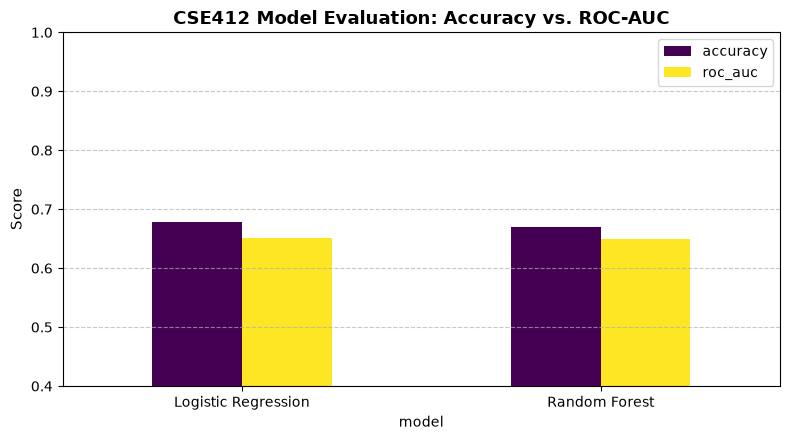


Sample Predictions (Random Forest Model):


,patient_nbr,label,prediction,probability
0,430092,0,0.0,"[0.6720717344078305, 0.3279282655921694]"
1,91160280,0,0.0,"[0.6412344554964154, 0.35876554450358455]"
2,26139852,0,0.0,"[0.5877221836597276, 0.4122778163402723]"
3,42593130,0,0.0,"[0.6160462915717038, 0.3839537084282961]"
4,99638541,0,0.0,"[0.6847515121460557, 0.31524848785394427]"
5,71304633,1,0.0,"[0.6833952738223756, 0.31660472617762425]"
6,1344069,0,0.0,"[0.6869566980067693, 0.31304330199323077]"
7,89045397,0,0.0,"[0.6624153346257945, 0.3375846653742055]"
8,41041530,0,0.0,"[0.5942044783952766, 0.40579552160472343]"
9,59903226,0,0.0,"[0.7000762717137292, 0.29992372828627073]"



=== Pipeline Outputs Saved ===
Saved: /home/manic/project/results/model_metrics.csv
Saved: /home/manic/project/results/sample_predictions.csv
Saved: /home/manic/project/results/run_info.json
Saved: /home/manic/project/results/model_comparison.png


In [11]:
import matplotlib.pyplot as plt

# Plot Model Comparison
plot_data = metrics_df[["accuracy", "roc_auc"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data.plot(kind="bar", ax=ax, colormap="viridis", width=0.5)
ax.set_title("CSE412 Model Evaluation: Accuracy vs. ROC-AUC", fontsize=13, fontweight="bold")
ax.set_ylabel("Score", fontsize=11)
ax.set_ylim(0.4, 1.0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=150)
plt.show()

# Sample Predictions Display
sample_preds = (rf_predictions.select("patient_nbr", "label", "prediction", "probability")
                .limit(10).toPandas())
print("\nSample Predictions (Random Forest Model):")
display(sample_preds)

# Save Outputs
metrics_path = RESULTS_DIR / "model_metrics.csv"
metrics_df.reset_index().to_csv(metrics_path, index=False)

preds_path = RESULTS_DIR / "sample_predictions.csv"
(rf_predictions.select("patient_nbr", "label", "prediction", "probability")
 .limit(1000).toPandas().to_csv(preds_path, index=False))

import json
run_info = {
    "course": "CSE412 — Big Data & Large-Scale Computing",
    "project": "Hospital Readmission Risk Prediction & Healthcare Analytics",
    "dataset_size": len(sample_df),
    "unique_patients": int(sample_df['patient_nbr'].nunique()),
    "train_rows": int(train_count),
    "test_rows": int(test_count),
    "hadoop_version": "3.4.1",
    "pig_version": "0.17.0",
    "hive_version": "4.2.0",
    "spark_version": spark.version,
    "models_evaluated": ["Logistic Regression", "Random Forest"],
    "metrics_file": str(metrics_path),
    "predictions_file": str(preds_path)
}
(RESULTS_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")

print("\n=== Pipeline Outputs Saved ===")
print("Saved:", metrics_path)
print("Saved:", preds_path)
print("Saved:", RESULTS_DIR / "run_info.json")
print("Saved:", RESULTS_DIR / "model_comparison.png")


## 7. Stage 7 — Troubleshooting and Reproducibility Checklist
- **HDFS SafeMode / Connection Refused:** Ensure NameNode & DataNode are started via `$HADOOP_HOME/sbin/start-dfs.sh`. Check `jps` to confirm.
- **HiveServer2 Port 10000:** Start HiveServer2 via `nohup hiveserver2 > logs/hiveserver2.log 2>&1 &`. Ensure no stale Derby `.lck` files exist in `$HOME/metastore_db/`.
- **Pig & Hive Execution Mode:** On single-node laptop/WSL with limited RAM (~4GB), use `mapreduce.framework.name=local` (Hadoop LocalJobRunner) so Pig and Hive run without needing the YARN ResourceManager and NodeManager daemons.
- **Java Compatibility:** Ensure `JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64` is exported prior to running Hadoop, Pig, Hive, and Spark.
- **Spark & Python Environment:** Use Python virtual environment at `~/project/.venv`. PySpark 3.5.9 matches Spark 3.5.9.
